In [9]:
# Nhập thư viện: Path xử lý đường dẫn; pandas xử lý bảng; numpy hỗ trợ tính toán; display hiển thị bảng.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
# Chọn thư mục chứa dữ liệu CSV; kiểm tra thư mục tồn tại trước khi đọc.
DATA_DIR = Path("DATA_SET")
assert DATA_DIR.is_dir(), "Cần đặt thư mục DATA_SET trong thư mục làm việc hoặc sửa DATA_DIR."


## 1. Data Inspection
Đọc tự động ba bảng CSV. Kiểm tra UTF-8 bằng chế độ strict trên toàn bộ tệp; giữ ISBN dạng chuỗi để bảo toàn số 0 đầu và ký tự X. Ba bảng khác cấu trúc nên dùng merge thay vì concat.

In [10]:
# Tạo từ điển lưu ba bảng dữ liệu theo tên Books, Users và Ratings.
tables = {}

# Lần lượt đọc từng tệp CSV trong thư mục dữ liệu.
for name in ["Books", "Users", "Ratings"]:
    path = DATA_DIR / f"{name}.csv"
    # Đọc toàn bộ tệp với UTF-8 strict để phát hiện lỗi mã hóa; pass chỉ bỏ qua nội dung từng dòng.
    with path.open(encoding="utf-8", errors="strict") as stream:
        for _ in stream:
            pass
    # Nạp CSV vào DataFrame; giữ ISBN dạng chuỗi để không mất số 0 đầu hoặc ký tự X.
    tables[name] = pd.read_csv(path, encoding="utf-8", dtype={"ISBN": "string"}, low_memory=False)

# Lấy ba DataFrame từ từ điển để dùng ở các bước sau.
books, users, ratings = [tables[n] for n in ["Books", "Users", "Ratings"]]

# Tóm tắt mỗi bảng: shape[0] là số dòng, shape[1] là số cột; duplicated đánh dấu dòng trùng.
summary = pd.DataFrame([{"Bảng": n, "Số dòng": d.shape[0], "Số cột": d.shape[1], "Dòng trùng": int(d.duplicated().sum())} for n,d in tables.items()])
display(summary)

# Hiển thị kiểu dữ liệu và số ô thiếu của từng cột trong mỗi bảng.
for name, frame in tables.items():
    print("\n", name)
    # dtypes lấy kiểu từng cột; astype(str) chuyển thông tin kiểu thành chuỗi, không đổi dữ liệu gốc.
    display(pd.DataFrame({"Kiểu": frame.dtypes.astype(str), "Thiếu": frame.isna().sum()}))


,Bảng,Số dòng,Số cột,Dòng trùng
0,Books,271360,8,0
1,Users,278858,3,0
2,Ratings,1149780,3,0



 Books


,Kiểu,Thiếu
ISBN,string,0
Book-Title,str,0
Book-Author,str,2
Year-Of-Publication,str,0
Publisher,str,2
Image-URL-S,str,0
Image-URL-M,str,0
Image-URL-L,str,3



 Users


,Kiểu,Thiếu
User-ID,int64,0
Location,str,0
Age,float64,110762



 Ratings


,Kiểu,Thiếu
User-ID,int64,0
ISBN,string,0
Book-Rating,int64,0


In [11]:
# Kiểm tra khóa ISBN và User-ID không bị thiếu và không trùng; assert báo lỗi nếu điều kiện sai.
assert books["ISBN"].notna().all() and books["ISBN"].is_unique
assert users["User-ID"].notna().all() and users["User-ID"].is_unique

# Đếm các dòng đánh giá trùng cặp người dùng–sách.
print("Trùng cặp User-ID, ISBN:", ratings.duplicated(["User-ID", "ISBN"]).sum())

# isin kiểm tra ISBN có trong bảng sách; ~ đảo kết quả; sum đếm các đánh giá không tìm thấy sách.
print("Đánh giá thiếu sách:", (~ratings["ISBN"].isin(books["ISBN"])).sum())

# Đếm các đánh giá có User-ID không xuất hiện trong bảng người dùng.
print("Đánh giá thiếu người dùng:", (~ratings["User-ID"].isin(users["User-ID"])).sum())

# Đếm số lượt cho từng mức điểm.
display(ratings.groupby("Book-Rating").size().rename("Số lượt").to_frame())

# Chuyển năm xuất bản sang số; errors="coerce" biến giá trị không chuyển được thành NaN.
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")

# loc chọn những dòng có năm thiếu hoặc không chuyển được thành số và các cột cần xem xét.
display(books.loc[year.isna(), ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]])

# Kiểm tra tuổi nhỏ nhất và lớn nhất để phát hiện giá trị bất thường, ví dụ 0 hoặc 244.
print("Tuổi nhỏ nhất/lớn nhất:", users["Age"].min(), users["Age"].max())


Trùng cặp User-ID, ISBN: 0
Đánh giá thiếu sách: 118644
Đánh giá thiếu người dùng: 0


,Số lượt
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...


Tuổi nhỏ nhất/lớn nhất: 0.0 244.0


## 2. Data Loading and Integration
Ratings là bảng trung tâm, mỗi dòng là một lượt đánh giá. Ratings có quan hệ nhiều–một với Users qua cột User-ID và với Books qua cột ISBN: một người dùng có thể có nhiều lượt đánh giá, một sách có thể được đánh giá nhiều lần. Dùng left join để giữ toàn bộ lượt đánh giá, kể cả khi không tìm thấy người dùng hoặc sách tương ứng. Tham số `validate='many_to_one'` kiểm tra khóa ở bảng Users hoặc Books không bị trùng; nếu bị trùng thì báo lỗi để tránh ghép làm tăng số dòng. Chỉ ghép các cột cần phân tích để giảm bộ nhớ.

In [12]:
# Chọn các cột thông tin sách cần ghép để giảm bộ nhớ.
book_columns = ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]

# Ghép đánh giá với sách theo ISBN; left giữ mọi đánh giá, Tham số `validate='many_to_one'` kiểm tra khóa ở bảng Users hoặc Books không bị trùng; nếu bị trùng thì báo lỗi để tránh ghép làm tăng số dòng. Chỉ ghép các cột cần phân tích để giảm bộ nhớ.; indicator ghi trạng thái khớp của mỗi lần ghép
integrated_raw = ratings.merge(books[book_columns], on="ISBN", how="left", validate="many_to_one", indicator="book_match")

# Ghép tiếp người dùng theo User-ID
integrated_raw = integrated_raw.merge(users, on="User-ID", how="left", validate="many_to_one", indicator="user_match")

# Đảm bảo việc ghép không làm thay đổi số dòng đánh giá.
assert len(integrated_raw) == len(ratings)

# Xem kích thước bảng ghép và số dòng khớp/không khớp với từng bảng phụ.
print("Kích thước bảng ghép:", integrated_raw.shape)
display(integrated_raw["book_match"].value_counts())
display(integrated_raw["user_match"].value_counts())
display(integrated_raw.head())


Kích thước bảng ghép: (1149780, 11)


book_match
both          1031136
left_only      118644
right_only          0
Name: count, dtype: int64

user_match
both          1149780
left_only           0
right_only          0
Name: count, dtype: int64

,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,book_match,Location,Age,user_match
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,both,"tyler, texas, usa",NaN,both
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,both,"seattle, washington, usa",NaN,both
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,both,"h, new south wales, australia",16.0,both
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,both,"rijeka, n/a, croatia",16.0,both
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,both,"rijeka, n/a, croatia",16.0,both


## 3. Data Cleaning
- Bỏ dòng trùng hoàn toàn; nếu còn nhiều điểm khác nhau cho cùng cặp người dùng–sách thì dừng để xem xét, không tự chọn một điểm.
- Loại riêng 3 dòng sách có năm không phải số khỏi bảng phân tích vì có dấu hiệu lệch trường; không suy đoán để sửa. Các đánh giá liên quan vẫn ở bảng ghép, được đánh dấu không có metadata sách sạch.
- Quy ước tuổi hợp lệ 5–100 và năm xuất bản 1450–2026; đây là ngưỡng đề xuất, không phải kết luận mọi giá trị ngoài khoảng đều sai. Năm 0 coi là chưa biết. Giữ giá trị thiếu dạng số, tạo cờ thiếu; chưa điền median trước khi chia train/test để tránh rò rỉ dữ liệu.
- Điền Unknown cho tác giả, nhà xuất bản và vị trí thiếu/rỗng; chuẩn hóa khoảng trắng. ISBN luôn là chuỗi.
- Giữ điểm 0 ở bảng tổng hợp. Với tập phân loại đề xuất, chỉ lấy điểm 1–10 và đặt liked = 1 nếu điểm ≥ 8. Ý nghĩa của điểm 0 cần xác nhận theo mô tả dataset; không tự gán 0 thành nhãn không thích.


In [13]:
# Bỏ các dòng trùng hoàn toàn và tạo bản sao để giữ nguyên ba bảng gốc.
books_clean = books.drop_duplicates().copy()
users_clean = users.drop_duplicates().copy()
ratings_clean = ratings.drop_duplicates().copy()


# Kiểm tra khóa sách duy nhất và không còn cặp người dùng–sách trùng cần xem xét.
assert books_clean["ISBN"].is_unique
assert not ratings_clean.duplicated(["User-ID", "ISBN"]).any(), "Cần xem xét đánh giá xung đột."


# Chuyển năm sang số; giá trị thiếu hoặc không chuyển được sẽ thành NaN.
parsed_year = pd.to_numeric(books_clean["Year-Of-Publication"], errors="coerce")


# Tách riêng các dòng có năm không chuyển được hoặc bị thiếu; loc lọc dòng theo điều kiện.
books_quarantine = books_clean.loc[parsed_year.isna()].copy()
books_clean = books_clean.loc[parsed_year.notna()].copy()


# Chuyển lại cột năm của bảng sách còn giữ để chuẩn hóa kiểu số.
y = pd.to_numeric(books_clean["Year-Of-Publication"], errors="coerce")
# Chỉ giữ năm 1450–2026; where thay các năm ngoài khoảng (kể cả 0) bằng giá trị thiếu.
books_clean["Year-Of-Publication"] = y.where(y.between(1450, 2026)).astype("Int64")
# Đánh giấu các năm nằm ngoài khoảng bị gán giá trị là NA
books_clean["Year_missing"] = books_clean["Year-Of-Publication"].isna()


# Chuyển tuổi sang số; giá trị không chuyển được thành giá trị thiếu.
a = pd.to_numeric(users_clean["Age"], errors="coerce")
# Theo quy ước của bài, chỉ giữ tuổi 5–100; tuổi như 244 thành <NA>, không xóa dòng người dùng.
users_clean["Age"] = a.where(a.between(5, 100)).astype("Float64")
# Đánh giấy người có tuổi ngoài khoảng hoặc bị thiếu  bị gán giá trị là NA
users_clean["Age_missing"] = users_clean["Age"].isna()


# Làm sạch các cột chữ: bỏ khoảng trắng ở hai đầu, đổi chuỗi rỗng thành thiếu rồi điền Unknown.
for frame, cols in [(books_clean, ["Book-Title", "Book-Author", "Publisher"]), (users_clean, ["Location"])]:
    for col in cols:
        frame[col] = frame[col].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
# Chuẩn hóa User-ID thành số nguyên ở cả hai bảng; errors="raise" báo lỗi nếu không chuyển được.
for frame in [users_clean, ratings_clean]:
    frame["User-ID"] = pd.to_numeric(frame["User-ID"], errors="raise").astype("int64")


# Chuyển điểm đánh giá sang số; kiểm tra mọi điểm nằm trong khoảng 0–10 và là số nguyên.
ratings_clean["Book-Rating"] = pd.to_numeric(ratings_clean["Book-Rating"], errors="raise")
assert ratings_clean["Book-Rating"].between(0, 10).all()
assert (ratings_clean["Book-Rating"] % 1 == 0).all()

# Lưu điểm bằng int8 vì khoảng 0–10 nhỏ, giúp tiết kiệm bộ nhớ.
ratings_clean["Book-Rating"] = ratings_clean["Book-Rating"].astype("int8")
# Báo số sách tách riêng, số tuổi thiếu và số năm thiếu sau khi làm sạch.
print("Sách tách riêng:", len(books_quarantine))
print("Tuổi thiếu sau xử lý:", users_clean["Age_missing"].sum())
print("Năm thiếu sau xử lý:", books_clean["Year_missing"].sum())


Sách tách riêng: 3
Tuổi thiếu sau xử lý: 112010
Năm thiếu sau xử lý: 4631


In [14]:
# Ghép lại các bảng đã làm sạch; left vẫn giữ các đánh giá chưa tìm thấy thông tin sách sạch.
data_clean = ratings_clean.merge(books_clean[book_columns + ["Year_missing"]], on="ISBN", how="left", validate="many_to_one", indicator="book_match")
data_clean = data_clean.merge(users_clean, on="User-ID", how="left", validate="many_to_one", indicator="user_match")

# Kiểm tra bảng ghép giữ nguyên số đánh giá và không sinh cặp người dùng–sách trùng.
assert len(data_clean) == len(ratings_clean)
assert not data_clean.duplicated(["User-ID", "ISBN"]).any()

# Tạo tập phân loại chỉ từ điểm 1–10; điểm 0 vẫn được giữ trong data_clean.
classification_data = data_clean.loc[data_clean["Book-Rating"].between(1, 10)].copy()

# Tạo nhãn liked: điểm từ 8 trở lên là 1 (thích), điểm 1–7 là 0(không thích).
classification_data["liked"] = (classification_data["Book-Rating"] >= 8).astype("int8")

# Xem kích thước dữ liệu và số đánh giá không có thông tin sách sạch (left_only).
print("Bảng sạch:", data_clean.shape)
print("Lượt đánh giá chưa có metadata sách sạch:", data_clean["book_match"].eq("left_only").sum())
print("Tập phân loại đề xuất:", classification_data.shape)

# Đếm số mẫu ở mỗi nhãn 0 và 1 để xem phân bố nhãn.
print(classification_data["liked"].value_counts().sort_index().to_string())

# Hiển thị 5 dòng đầu của bảng sạch để kiểm tra kết quả.
display(data_clean.head())


Bảng sạch: (1149780, 13)
Lượt đánh giá chưa có metadata sách sạch: 118648
Tập phân loại đề xuất: (433671, 14)
liked
0    183784
1    249887


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Year_missing,book_match,Location,Age,Age_missing,user_match
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,False,both,"tyler, texas, usa",<NA>,True,both
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,False,both,"seattle, washington, usa",<NA>,True,both
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,False,both,"h, new south wales, australia",16.0,False,both
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both


### Chuyển sang EDA và xây dựng mô hình
Các bảng sạch được dùng ở phần 4–5 dưới đây. Đây là bài toán dự đoán một lượt đánh giá có điểm ≥ 8 hay không, trong nhóm đánh giá có điểm 1–10. Không suy rộng kết quả thành hành vi của tất cả người dùng hoặc khả năng họ sẽ mua/đọc sách. Điểm 0 được giữ ở bảng tổng hợp nhưng chưa dùng làm nhãn phân loại vì ý nghĩa cần được xác nhận.

## 4. Exploratory Data Analysis (EDA)

### 4.1. PHÂN TÍCH ĐỘ TUỔI NGƯỜI DÙNG


Thống kê tuổi người dùng:
count     166848.0
mean     34.746638
std      13.633051
min            5.0
25%           24.0
50%           32.0
75%           44.0
max          100.0
Name: Age, dtype: Float64
Số người dùng thiếu tuổi: 112010
Tỷ lệ người dùng thiếu tuổi: 40.17%


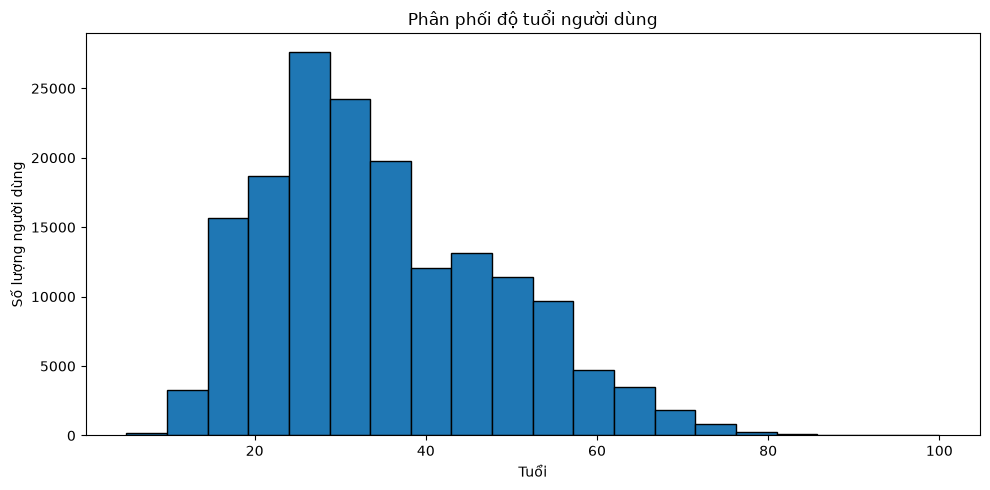

In [15]:
# Chuyển tuổi sang kiểu số để thống kê.
# Tuổi thiếu hoặc không chuyển được thành số sẽ trở thành NaN.
user_age = pd.to_numeric(users_clean["Age"],errors="coerce")
# Thống kê tuổi của người dùng.
print("\nThống kê tuổi người dùng:")
print(user_age.describe())
# Đếm số người dùng thiếu tuổi và tính tỷ lệ phần trăm.
missing_age_count = user_age.isna().sum()
missing_age_percentage = user_age.isna().mean() * 100
print("Số người dùng thiếu tuổi:", missing_age_count)
print(f"Tỷ lệ người dùng thiếu tuổi: {missing_age_percentage:.2f}%")
# Vẽ biểu đồ phân phối tuổi, bỏ qua các giá trị thiếu.
plt.figure(figsize=(10, 5))
user_age.dropna().plot(kind="hist",bins=20,edgecolor="black")
plt.title("Phân phối độ tuổi người dùng")
plt.xlabel("Tuổi")
plt.ylabel("Số lượng người dùng")
plt.tight_layout()
plt.show()


### 4.2. PHÂN TÍCH PHÂN PHỐI ĐIỂM ĐÁNH GIÁ

Thống kê lượt đánh giá Like và Unlike:


,Số lượt đánh giá,Tỷ lệ (%)
1,249887,57.62
0,183784,42.38


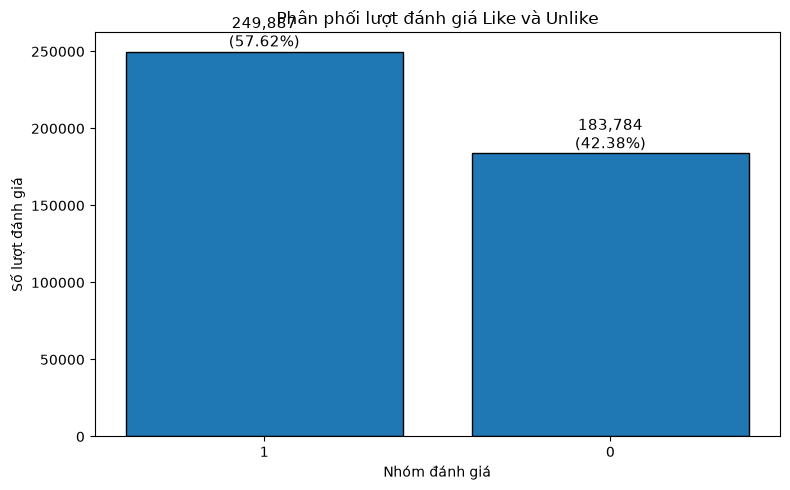

In [16]:

# Đếm số lượt đánh giá thuộc mỗi nhóm:
# liked = 1: Like (điểm 8–10)
# liked = 0: Unlike (điểm 1–7)
like_unlike_counts = (classification_data["liked"].value_counts().reindex([1, 0], fill_value=0))
# Đổi nhãn số thành tên nhóm để biểu đồ dễ đọc hơn.
like_unlike_counts.index = ["1", "0"]
# Tính tỷ lệ phần trăm của mỗi nhóm trên tổng số lượt đánh giá.
like_unlike_percentages = (like_unlike_counts / like_unlike_counts.sum() * 100)
# Tổng hợp số lượng và tỷ lệ thành bảng thống kê.
like_unlike_summary = pd.DataFrame({"Số lượt đánh giá": like_unlike_counts,"Tỷ lệ (%)": like_unlike_percentages})
# Hiển thị bảng thống kê để kiểm tra kết quả.
print("Thống kê lượt đánh giá Like và Unlike:")
display(like_unlike_summary.round(2))
# Vẽ biểu đồ cột thể hiện số lượng của hai nhóm.
plt.figure(figsize=(8, 5))
bars = plt.bar(like_unlike_counts.index,like_unlike_counts.values,edgecolor="black")
# Ghi số lượt đánh giá và tỷ lệ phần trăm lên mỗi cột.
for bar, count, percentage in zip(bars,like_unlike_counts.values,like_unlike_percentages.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )
# Đặt tiêu đề, tên trục và căn chỉnh biểu đồ.
plt.title("Phân phối lượt đánh giá Like và Unlike")
plt.xlabel("Nhóm đánh giá")
plt.ylabel("Số lượt đánh giá")
plt.tight_layout()
plt.show()

Số lượt đánh giá theo điểm:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Tỷ lệ phần trăm theo điểm:
Book-Rating
1      0.41
2      0.64
3      1.38
4      2.05
5     11.75
6      8.51
7     17.63
8     23.92
9     15.57
10    18.13
Name: proportion, dtype: float64


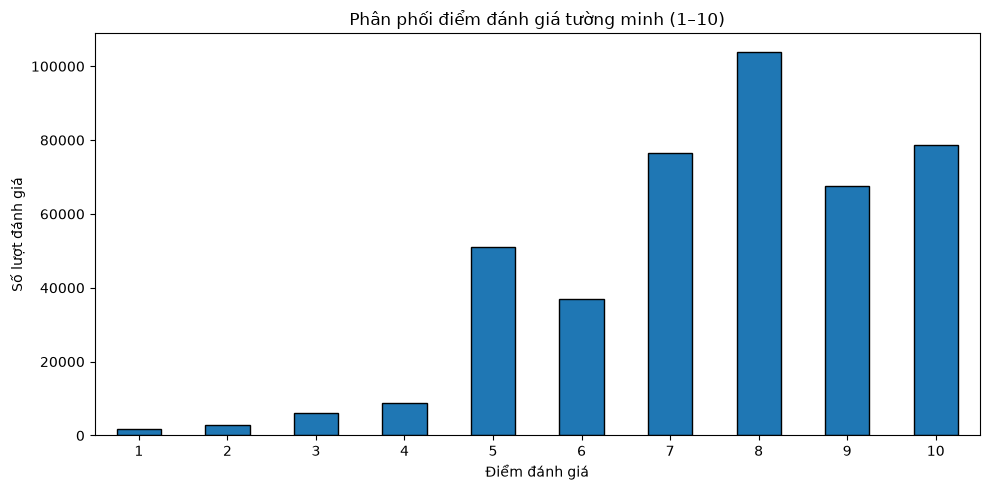

In [17]:
# Tách các lượt đánh giá có điểm tường minh từ 1 đến 10.
# Giữ nguyên ratings_clean để không làm thay đổi dữ liệu gốc đã làm sạch.
explicit_ratings = ratings_clean.loc[ratings_clean["Book-Rating"].between(1, 10)].copy()
# Đếm số lượt đánh giá theo từng điểm từ 1 đến 10.
explicit_rating_counts = (explicit_ratings["Book-Rating"].value_counts().sort_index())
# Tính tỷ lệ phần trăm của từng điểm trong nhóm đánh giá tường minh.
explicit_rating_percentages = (explicit_ratings["Book-Rating"].value_counts(normalize=True).sort_index() * 100)
# Hiển thị số lượng và tỷ lệ để so sánh các mức điểm.
print("Số lượt đánh giá theo điểm:")
print(explicit_rating_counts)
print("\nTỷ lệ phần trăm theo điểm:")
print(explicit_rating_percentages.round(2))
# Vẽ biểu đồ phân phối điểm đánh giá tường minh.
plt.figure(figsize=(10, 5))
explicit_rating_counts.plot(kind="bar", edgecolor="black")
plt.title("Phân phối điểm đánh giá tường minh (1–10)")
plt.xlabel("Điểm đánh giá")
plt.ylabel("Số lượt đánh giá")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.3.PHÂN TÍCH NGƯỜI DÙNG ĐÁNH GIÁ ĐÁNH GIÁ NHIỀU NHẤT

In [18]:
# Chỉ giữ các lượt đánh giá có điểm từ 1 đến 10.
# Book-Rating = 0 không được tính vì không phải điểm đánh giá rõ ràng.
explicit_ratings = ratings_clean.loc[ratings_clean["Book-Rating"].between(1, 10)].copy()
# Đếm số lượt đánh giá có điểm của từng người dùng.
user_rating_counts = (explicit_ratings.groupby("User-ID").size().reset_index(name="Number_of_Ratings"))
# Sắp xếp số lượt đánh giá từ cao xuống thấp và lấy 10 người dùng đầu tiên.
top_10_users = (user_rating_counts.sort_values("Number_of_Ratings", ascending=False).head(10).reset_index(drop=True))
# Đánh số thứ hạng từ 1 đến 10 để dễ theo dõi.
top_10_users.index = top_10_users.index + 1
top_10_users.index.name = "Rank"
# Hiển thị bảng kết quả.
print("TOP 10 NGƯỜI DÙNG CÓ NHIỀU LƯỢT ĐÁNH GIÁ CÓ ĐIỂM NHẤT:")
display(top_10_users)

TOP 10 NGƯỜI DÙNG CÓ NHIỀU LƯỢT ĐÁNH GIÁ CÓ ĐIỂM NHẤT:


,User-ID,Number_of_Ratings
Rank,,
1,11676,8524
2,98391,5802
3,153662,1969
4,189835,1906
5,23902,1395
6,76499,1036
7,171118,1035
8,235105,1023
9,16795,968


### 4.4.PHÂN TÍCH CÁC SÁCH ĐƯỢC ĐÁNH GIÁ NHIỀU NHẤT

In [19]:
# Đếm số lượt đánh giá cho mỗi ISBN.
# Kết quả thể hiện mức độ xuất hiện của sách trong bảng Ratings.
book_rating_counts = (ratings_clean.groupby("ISBN").size().sort_values(ascending=False))
# Lấy 10 ISBN có nhiều lượt đánh giá nhất.
top_10_isbns = book_rating_counts.head(10)
# Tạo bảng thông tin sách để bổ sung tên sách cho kết quả.
# Chỉ lấy ISBN và tên sách để tránh ghép các cột không cần thiết.
book_titles = books_clean[["ISBN", "Book-Title"]].drop_duplicates(subset=["ISBN"])
# Ghép số lượt đánh giá với tên sách tương ứng.
top_10_books = (top_10_isbns.rename("Number_of_Ratings").reset_index().merge(book_titles, on="ISBN", how="left"))
# Hiển thị 10 sách có nhiều lượt đánh giá nhất.
print("\nTop 10 sách có nhiều lượt đánh giá nhất:")
display(top_10_books)



Top 10 sách có nhiều lượt đánh giá nhất:


,ISBN,Number_of_Ratings,Book-Title
0,0971880107,2502,Wild Animus
1,0316666343,1295,The Lovely Bones: A Novel
2,0385504209,883,The Da Vinci Code
3,0060928336,732,Divine Secrets of the Ya-Ya Sisterhood: A Novel
4,0312195516,723,The Red Tent (Bestselling Backlist)
5,044023722X,647,A Painted House
6,0679781587,639,<NA>
7,0142001740,615,The Secret Life of Bees
8,067976402X,614,Snow Falling on Cedars
9,0671027360,586,Angels &amp; Demons


### 4.5. PHÂN TÍCH MỨC ĐIỂM ĐÁNH GIÁ CỦA SÁCH

In [20]:
# Chỉ lấy những lượt đánh giá từ 1 đến 10.
# Điểm 0 không được đưa vào phép tính điểm trung bình.
explicit_rating_data = ratings_clean.loc[ratings_clean["Book-Rating"].between(1, 10)].copy()
# Tính điểm trung bình và số lượt đánh giá cho từng ISBN.
book_rating_summary = (explicit_rating_data.groupby("ISBN")["Book-Rating"].agg(["mean", "count"]).reset_index())
# Đổi tên cột để kết quả dễ đọc hơn.
book_rating_summary.columns = ["ISBN","Average_Rating","Number_of_Ratings"]
# Chỉ xét sách có ít nhất 10 lượt đánh giá để hạn chế
# việc sách có quá ít lượt đánh giá đứng đầu do ngẫu nhiên.
popular_books = book_rating_summary.loc[book_rating_summary["Number_of_Ratings"] >= 10].copy()
# Sắp xếp theo điểm trung bình giảm dần và lấy 10 sách đầu tiên.
top_10_best_books = popular_books.sort_values(by=["Average_Rating", "Number_of_Ratings"],ascending=[False, False]).head(10)
# Bổ sung tên sách để dễ diễn giải kết quả.
top_10_best_books = top_10_best_books.merge(book_titles,on="ISBN",how="left")
# Sắp xếp theo điểm trung bình giảm dần và lấy 10 sách đầu tiên.
top_10_worst_books = popular_books.sort_values(by=["Average_Rating", "Number_of_Ratings"],ascending=[True, False]).head(10)
# Bổ sung tên sách để dễ diễn giải kết quả.
top_10_worst_books = top_10_worst_books.merge(book_titles,on="ISBN",how="left")
# Hiển thị 10 sách có điểm trung bình cao nhất trong nhóm đủ lượt đánh giá.
print("\nTop 10 sách có điểm trung bình cao nhất (ít nhất 10 lượt đánh giá):")
display(top_10_best_books)
print("---------------------")
print("\nTop 10 sách có điểm trung bình thấp nhất (ít nhất 10 lượt đánh giá):")
display(top_10_worst_books)



Top 10 sách có điểm trung bình cao nhất (ít nhất 10 lượt đánh giá):


,ISBN,Average_Rating,Number_of_Ratings,Book-Title
0,1888054557,10.000000,11,Postmarked Yesteryear: 30 Rare Holiday Postcards
1,0836213319,9.923077,13,Dilbert: A Book of Postcards
2,0439425220,9.869565,23,Harry Potter and the Chamber of Secrets Postca...
3,0312992416,9.800000,10,Kiss of the Night (A Dark-Hunter Novel)
4,0394823370,9.800000,10,The Lorax
5,0394800389,9.785714,14,Fox in Socks (I Can Read It All by Myself Begi...
6,0060256656,9.750000,20,The Giving Tree
7,0312099045,9.727273,11,Route 66 Postcards: Greetings from the Mother ...
8,0618002235,9.720000,25,"The Two Towers (The Lord of the Rings, Part 2)"
9,8826703132,9.714286,21,<NA>


---------------------

Top 10 sách có điểm trung bình thấp nhất (ít nhất 10 lượt đánh giá):


,ISBN,Average_Rating,Number_of_Ratings,Book-Title
0,0971880107,4.390706,581,Wild Animus
1,3442452031,4.900000,10,Soloalbum.
2,1401088945,5.000000,10,Ground Zero and Beyond
3,0679463321,5.066667,15,Killing Time: A Novel of the Future
4,0349111863,5.076923,13,Sex and the City
5,0142000981,5.133333,15,Coal: A Human History
6,0871138190,5.166667,12,Four Blondes
7,3518368001,5.181818,11,Neue Leiden Des Jungen
8,0312288115,5.250000,20,Confessions of a Sociopathic Social Climber : ...
9,0802132952,5.285714,21,Naked Lunch


### 4.6. PHÂN TÍCH MỐI QUAN HỆ GIỮA ĐỘ TUỔI VÀ NHÃN ĐÁNH GIÁ

Thống kê độ tuổi theo nhãn:


,count,mean,median,std
Nhãn 0 (điểm 1–7),121004,35.99,34.0,12.21
Nhãn 1 (điểm 8–10),182096,36.78,35.0,12.46


Tỷ lệ nhãn trong từng nhóm tuổi (%):


liked,Nhãn 0 (điểm 1–7),Nhãn 1 (điểm 8–10)
Age_Group,,
5–18,41.49,58.51
19–30,40.26,59.74
31–45,41.54,58.46
46–60,35.96,64.04
61–100,39.12,60.88


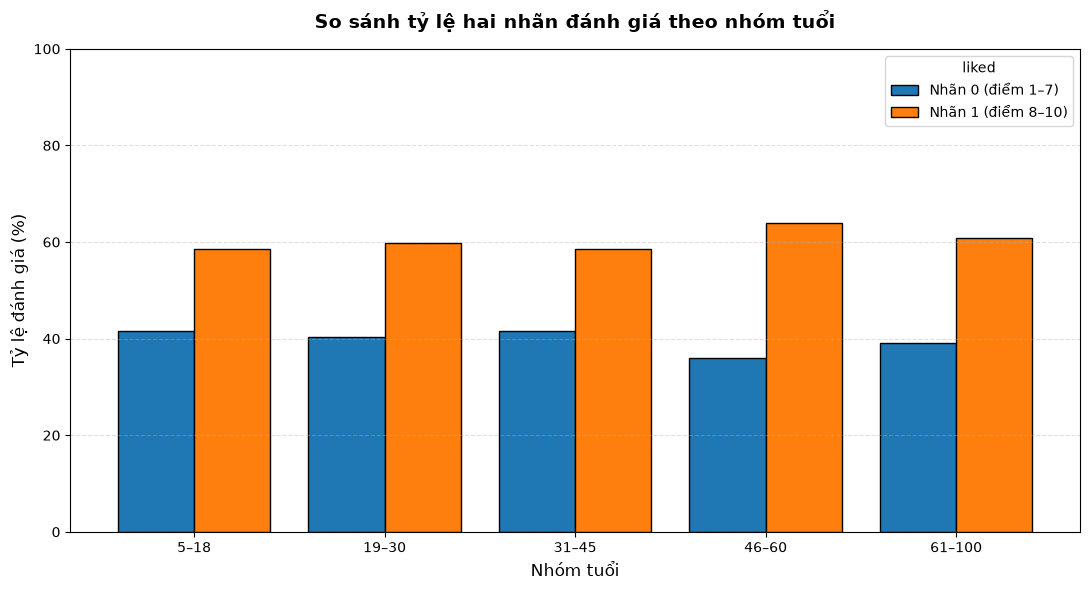

In [21]:
# Tạo bản sao để không làm thay đổi classification_data hiện có.
age_label_data = classification_data.copy()
# Chuyển Age về dạng số; giá trị không hợp lệ sẽ thành NaN.
age_label_data["Age"] = pd.to_numeric(age_label_data["Age"],errors="coerce")
# Chỉ giữ độ tuổi hợp lệ trong khoảng 5–100.
age_label_data.loc[~age_label_data["Age"].between(5, 100),"Age"] = np.nan
# Thống kê số lượng, trung bình và trung vị độ tuổi theo nhãn.
age_label_summary = (age_label_data.groupby("liked")["Age"].agg(["count", "mean", "median", "std"]))
# Đổi tên nhãn để phân biệt rõ ý nghĩa.
age_label_summary.index = ["Nhãn 0 (điểm 1–7)","Nhãn 1 (điểm 8–10)"]
print("Thống kê độ tuổi theo nhãn:")
display(age_label_summary.round(2))
# Tạo các nhóm tuổi để so sánh tỷ lệ nhãn giữa các nhóm.
age_label_data["Age_Group"] = pd.cut(age_label_data["Age"],bins=[4, 18, 30, 45, 60, 100],labels=["5–18", "19–30", "31–45", "46–60", "61–100"])
# Tính tỷ lệ nhãn 0 và 1 trong từng nhóm tuổi.
age_label_distribution = pd.crosstab(age_label_data["Age_Group"],age_label_data["liked"],normalize="index") * 100
# Đổi tên cột cho dễ đọc.
age_label_distribution = age_label_distribution.rename(columns={0: "Nhãn 0 (điểm 1–7)",1: "Nhãn 1 (điểm 8–10)"})
print("Tỷ lệ nhãn trong từng nhóm tuổi (%):")
display(age_label_distribution.round(2))
# Tạo biểu đồ cột; mỗi nhóm tuổi có hai cột tương ứng với hai nhãn(# Đặt hai cột cạnh nhau thay vì chồng lên nhau).
ax = age_label_distribution.plot(kind="bar",stacked=False,             figsize=(11, 6),width=0.8,edgecolor="black")
# Thêm tiêu đề và tên các trục.
ax.set_title("So sánh tỷ lệ hai nhãn đánh giá theo nhóm tuổi",fontsize=14,fontweight="bold",pad=15)
ax.set_xlabel("Nhóm tuổi", fontsize=12)
ax.set_ylabel("Tỷ lệ đánh giá (%)", fontsize=12)
# Giữ nguyên thứ tự và cách hiển thị tên các nhóm tuổi.
ax.tick_params(axis="x", rotation=0)
# Đặt giới hạn trục tung từ 0 đến 100% để dễ so sánh.
ax.set_ylim(0, 100)
# Hiển thị đường lưới ngang để dễ đọc giá trị.
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 4.7. PHÂN TÍCH MỐI QUAN HỆ GIỮA ĐỘ TUỔI VÀ SỐ LƯỢT ĐÁNH GIÁ SÁCH

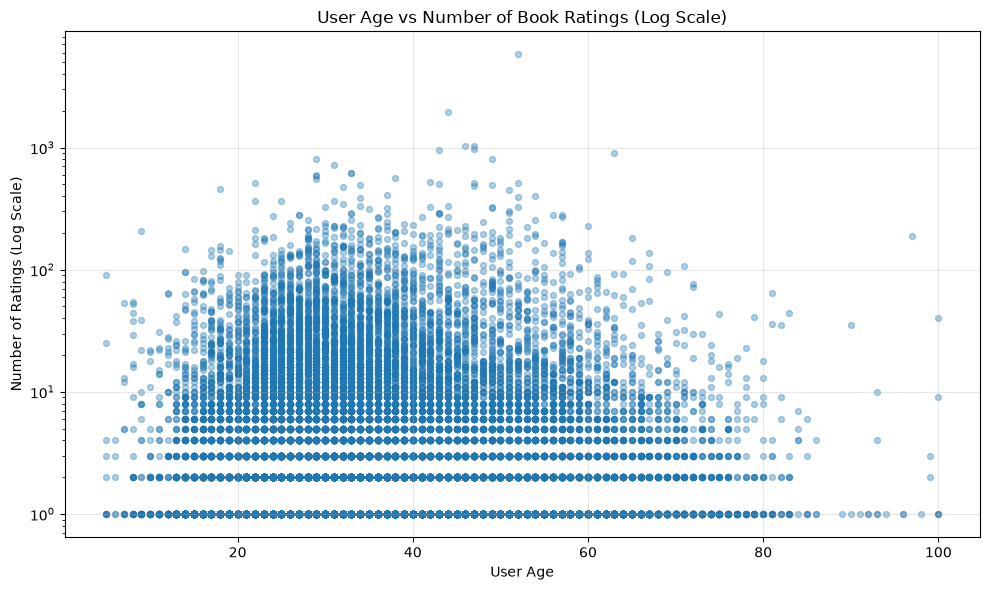

In [22]:
# Tạo biểu đồ Log Scale
# Lấy các bản ghi có tuổi hợp lệ.
age_rating_data = classification_data.dropna(subset=["Age", "User-ID"]).copy()
# Đếm số lượt đánh giá của mỗi người dùng.
user_rating_counts = (age_rating_data.groupby(["User-ID", "Age"]).size().reset_index(name="Number_of_Ratings"))
# Vẽ biểu đồ Scatter.
plt.figure(figsize=(10, 6))
plt.scatter(user_rating_counts["Age"],user_rating_counts["Number_of_Ratings"],alpha=0.35, s=18)
# Dùng thang logarit để thể hiện rõ các giá trị nhỏ và lớn.
plt.yscale("log")
plt.title("User Age vs Number of Book Ratings (Log Scale)")
plt.xlabel("User Age")
plt.ylabel("Number of Ratings (Log Scale)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

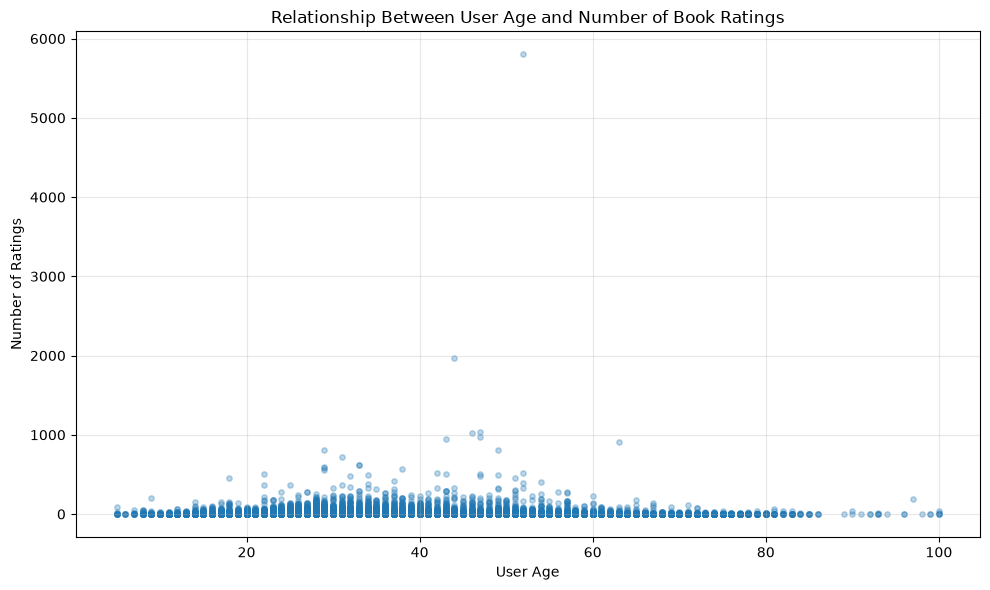

In [23]:
# Tạo biểu đồ Scatter.
plt.figure(figsize=(10, 6))
plt.scatter(user_rating_counts["Age"],user_rating_counts["Number_of_Ratings"],alpha=0.3,s=15)
# Đặt tên biểu đồ và các trục.
plt.title("Relationship Between User Age and Number of Book Ratings")
plt.xlabel("User Age")
plt.ylabel("Number of Ratings")
# Hiển thị lưới để dễ quan sát.
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.8. EDA Summary